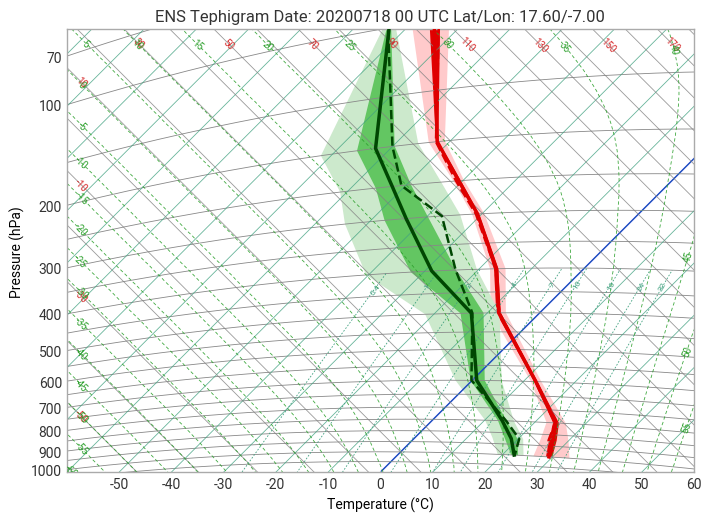

In [1]:
import earthkit.data as ekd
import earthkit.plots as ekp
from earthkit.meteo import thermo
from earthkit.plots.thermodynamic import ThermoGrid

# read ENS data: control (member 0) and 50 perturbed members on pressure levels
data = ekd.from_source(
    "url", "https://sites.ecmwf.int/repository/metview/test-data/gallery/ens_prof.grib"
)

# thermo_grib(point_extraction="nearest_gridpoint", coordinates=[17.51, -7.04])
ds = data.to_xarray()
prof = ds.sel(latitude=17.51, longitude=-7.04, method="nearest")

t = prof["t"]  # K, dims (member, level)
td = thermo.dewpoint_from_specific_humidity(prof["q"], prof["level"] * 100.0)  # K

# ENS statistics over all 51 members (control + perturbed):
# mean, full range (outer area) and 25-75 percentile range (inner area)
quantiles = [0.0, 0.25, 0.75, 1.0]
t_q = t.quantile(quantiles, dim="member", keep_attrs=True)
td_q = td.quantile(quantiles, dim="member", keep_attrs=True)
t_mean = t.mean("member", keep_attrs=True)
td_mean = td.mean("member", keep_attrs=True)

# mthermogrid(...), drawn in front of the data (thermo_grid_layer_mode="foreground")
teal = "#42a281"
grid = ThermoGrid(
    isotherms={"color": teal},
    dry_adiabats={"color": "grey", "label_frequency": 2},
    mixing_ratios={"color": teal, "label_style": {"color": teal, "fontsize": 6}},
    layer="foreground",
)

# thermoview(type="tephigram", ...)
tephi = ekp.Tephigram(pressure_range=(1015, 100), grid=grid)

# thermo_isotherm_reference_colour="blue"
tephi.isotherm(0, color="blue", linewidth=1)

# xy_area: outer area = full ENS range, inner area = 25-75 percentile range
tephi.envelope(t_q.sel(quantile=0.0), t_q.sel(quantile=1.0), color="#ffcacb", alpha=1)
tephi.envelope(t_q.sel(quantile=0.25), t_q.sel(quantile=0.75), color="#e20000", alpha=1)
tephi.envelope(td_q.sel(quantile=0.0), td_q.sel(quantile=1.0), color="#cce9cc", alpha=1)
tephi.envelope(td_q.sel(quantile=0.25), td_q.sel(quantile=0.75), color="#63c662", alpha=1)

# xy_curve: ENS mean (solid) and control (dashed) profiles
t_line, td_line = "#de0000", "#004702"
tephi.temperature(t_mean, color=t_line, linewidth=2.5)
tephi.dewpoint(td_mean, color=td_line, linestyle="-", linewidth=2.5)
tephi.temperature(t.sel(member="0"), color=t_line, linestyle="--", linewidth=1.8)
tephi.dewpoint(td.sel(member="0"), color=td_line, linestyle="--", linewidth=1.8)

# mtext: title from the GRIB metadata
field = data.to_fieldlist()[0]
tephi.title(
    f"ENS Tephigram Date: {field.get('time.base_datetime'):%Y%m%d %H} UTC "
    f"Lat/Lon: {prof.latitude.item():.2f}/{prof.longitude.item():.2f}"
)

# setoutput(pdf_output(output_name="ens_tephigram"))
tephi.show()